# Chapter 21 — Making Graphs and Manipulating Images

Source: [Automate the Boring Stuff with Python, 3rd Ed. — Chapter 21](https://automatetheboringstuff.com/3e/chapter21.html)

**Setup note:** Needs `pip install pillow matplotlib`.

This notebook favors *reading* over *writing*: each section has a short explanation followed by real, runnable code. Read it, run it, tweak a value and re-run it — that's the fastest way to build reading fluency.

---


## 21.1 Opening and inspecting images with Pillow

`PIL.Image.open(path)` (Pillow is imported as `PIL`) loads an image; `.size`, `.format`, and `.mode` describe its dimensions, file type, and color mode (e.g. `'RGB'`, `'RGBA'`).


In [1]:
from PIL import Image

img = Image.new('RGB', (200, 100), color='skyblue')
print(img.size, img.mode, img.format)
img.save('demo_image.png')


(200, 100) RGB None


## 21.2 Cropping, resizing, and rotating

`.crop((left, top, right, bottom))` cuts out a rectangular region, `.resize((w, h))` scales the image, and `.rotate(degrees)` rotates it — each returns a *new* Image object rather than modifying in place.


In [2]:
from PIL import Image

img = Image.open('demo_image.png')
cropped = img.crop((0, 0, 100, 50))
resized = img.resize((400, 200))
rotated = img.rotate(90, expand=True)
print(cropped.size, resized.size, rotated.size)


(100, 50) (400, 200) (100, 200)


## 21.3 Drawing shapes and text on an image

`ImageDraw.Draw(img)` returns a drawing context with methods like `.rectangle()`, `.ellipse()`, `.line()`, and `.text()` to annotate or generate images programmatically.


In [3]:
from PIL import Image, ImageDraw

img = Image.open('demo_image.png')
draw = ImageDraw.Draw(img)
draw.rectangle((10, 10, 60, 40), outline='red', width=3)
draw.text((70, 20), 'Hello!', fill='black')
img.save('demo_image_annotated.png')
print('saved demo_image_annotated.png')

import os
os.remove('demo_image.png')
os.remove('demo_image_annotated.png')


saved demo_image_annotated.png


## 21.4 A quick chart with matplotlib

While the book focuses on image editing, plotting data as a chart is a closely related "turn data into a picture" task, and `matplotlib` is Python's most common charting library.


saved demo_chart.png


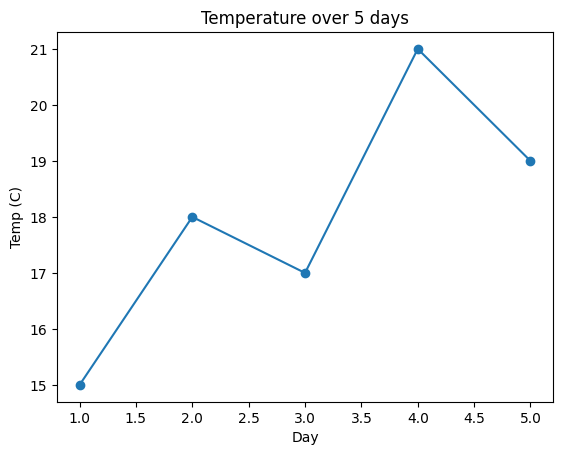

In [4]:
import matplotlib.pyplot as plt

days = [1, 2, 3, 4, 5]
temps = [15, 18, 17, 21, 19]
plt.plot(days, temps, marker='o')
plt.title('Temperature over 5 days')
plt.xlabel('Day')
plt.ylabel('Temp (C)')
plt.savefig('demo_chart.png')
print('saved demo_chart.png')

import os
os.remove('demo_chart.png')


## 21.5 Copying and pasting images with pyperclipimg

`pyperclip` (Chapter 8) only handles text. Its companion module `pyperclipimg` does the same job for **images**: `pyperclipimg.copy(image)` puts a Pillow `Image` object onto the OS clipboard (so you could paste it directly into another app), and `pyperclipimg.paste()` returns whatever image is currently on the clipboard as a Pillow `Image`, or `None` if the clipboard doesn't hold an image.

**Environment note:** same as `pyperclip` in Chapter 8, this needs a real OS clipboard mechanism this headless sandbox doesn't have.

In [5]:
from PIL import Image

img = Image.new('RGB', (60, 60), color='purple')

try:
    import pyperclipimg
    pyperclipimg.copy(img)
    pasted = pyperclipimg.paste()
    print('Round-trip worked. Pasted image size:', pasted.size if pasted else None)
except Exception as e:
    print(f'{type(e).__name__} in this sandbox (expected, no OS clipboard available here):', e)
    print('On your own desktop, pyperclipimg.copy(img)/.paste() work directly with the real clipboard.')


NotImplementedError in this sandbox (expected, no OS clipboard available here): pyperclipimg on Linux requires the xclip or wl-copy command. Run either `sudo apt install xclip` or `sudo apt install wl-clipboard` and restart
On your own desktop, pyperclipimg.copy(img)/.paste() work directly with the real clipboard.
